# Māori Research Paper Classification with Gemini API

In [ ]:
MODEL = "gemini-2.5-flash"

In [ ]:
!pip install google-genai

In [ ]:
from google.colab import auth
auth.authenticate_user()

In [ ]:
# from google import genai
# from google.genai.types import HttpOptions

# client = genai.Client(vertexai=True, project="gen-lang-client-0900489206", location="us-central1")
# response = client.models.generate_content(
#     model=MODEL,
#     contents="How does AI work?",
# )
# print(response.text)

Artificial Intelligence (AI) works by enabling machines to **simulate human-like intelligence** to perform tasks. Instead of being explicitly programmed for every single step, AI systems are designed to **learn from data, identify patterns, and make decisions or predictions.**

Here's a breakdown of how it generally works:

### The Core Idea: Learning from Data

At its heart, AI (especially modern AI) is about **learning from examples**. Imagine teaching a child: you show them many pictures of cats and dogs, pointing out which is which. Over time, the child learns to distinguish them on their own. AI works similarly, but on a much larger scale and with algorithms.

### Key Pillars of How AI Works:

1.  **Data: The Fuel**
    *   AI systems need vast amounts of data to learn. This data can be text, images, audio, video, sensor readings, numbers, etc.
    *   **Quality and Quantity:** The more relevant and high-quality data an AI system is trained on, the better it will perform.
    *   

In [ ]:
from google import genai

# initialize once (reuse this across your app)
client = genai.Client(
    vertexai=True,
    project="gen-lang-client-0900489206",
    location="us-central1"
)

def count_tokens(text: str, model: str = "gemini-3-flash") -> int:
    response = client.models.count_tokens(
        model=model,
        contents=text
    )
    return response.total_tokens

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

dataset_path = '/content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/stage2_colab/Datasets/6_cleaned_hashed_dataset_16590.csv'
df = pd.read_csv(dataset_path)

print(f"Successfully loaded dataset from: {dataset_path}")
display(df.head())

Successfully loaded dataset from: /content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/stage2_colab/Datasets/6_cleaned_hashed_dataset_16590.csv


,title,authors,year,subjects,abstract,text,record_id_hash
0,Characterizing porous microaggregates and soil...,"Huang, Doreen Yu-Tuan",2021,Science & Technology,Allophanic tephra-derived soils can sequester ...,Characterizing porous microaggregates and soil...,fefa3d488de2a37e6bac3bb97033e389a7f3274f1626b8...
1,Sexual Desire in Women Presenting for Antiandr...,"Conaglen, Helen M.",2003,antiandrogen therapy,Women presenting with hirsuties/polycystic ova...,Sexual Desire in Women Presenting for Antiandr...,7e6086aed791d4d7c9e56b862f4a36aaaf39e6f0de8d15...
2,Aluminium content in near-shore sediments of L...,"Tempero, Grant Wayne",2019,NaN,The application of alum (aluminium sulphate) i...,Aluminium content in near-shore sediments of L...,b9b3e816cb791407640fa08a033bc2b7b09c4fb9a7438c...
3,Introduction,"Houlahan, Mark",2019,NaN,"When Dr Johnson, the 18• century critic, was a...","Introduction When Dr Johnson, the 18• century ...",4c3bde78419fd2dcf4944c39180e42d828f641c5ac05a8...
4,Is peer review in academic publishing still wo...,"Jackson, Liz",2018,Peer review,Peer review is central to academic publishing....,Is peer review in academic publishing still wo...,85ee578de741354f56d5fae8970ad2c89319d64b6efdce...


In [ ]:
# Get the number of rows and columns
num_rows, num_cols = df.shape
print(f"The DataFrame has {num_rows} rows and {num_cols} columns.")

The DataFrame has 16590 rows and 7 columns.


After running the cell above and following the authentication steps, your Google Drive will be accessible at `/content/drive`. Please tell me the full path to your dataset file (e.g., `/content/drive/MyDrive/my_data.csv`) and its type (e.g., CSV, Excel, JSON).

In [ ]:
df.columns

Index(['title', 'authors', 'year', 'subjects', 'abstract', 'text',
       'record_id_hash'],
      dtype='object')

In [ ]:
df.head(5)

,title,authors,year,subjects,abstract,text,record_id_hash
0,Characterizing porous microaggregates and soil...,"Huang, Doreen Yu-Tuan",2021,Science & Technology,Allophanic tephra-derived soils can sequester ...,Characterizing porous microaggregates and soil...,fefa3d488de2a37e6bac3bb97033e389a7f3274f1626b8...
1,Sexual Desire in Women Presenting for Antiandr...,"Conaglen, Helen M.",2003,antiandrogen therapy,Women presenting with hirsuties/polycystic ova...,Sexual Desire in Women Presenting for Antiandr...,7e6086aed791d4d7c9e56b862f4a36aaaf39e6f0de8d15...
2,Aluminium content in near-shore sediments of L...,"Tempero, Grant Wayne",2019,NaN,The application of alum (aluminium sulphate) i...,Aluminium content in near-shore sediments of L...,b9b3e816cb791407640fa08a033bc2b7b09c4fb9a7438c...
3,Introduction,"Houlahan, Mark",2019,NaN,"When Dr Johnson, the 18• century critic, was a...","Introduction When Dr Johnson, the 18• century ...",4c3bde78419fd2dcf4944c39180e42d828f641c5ac05a8...
4,Is peer review in academic publishing still wo...,"Jackson, Liz",2018,Peer review,Peer review is central to academic publishing....,Is peer review in academic publishing still wo...,85ee578de741354f56d5fae8970ad2c89319d64b6efdce...


In [ ]:
pip install datasets

In [ ]:
from datasets import Dataset
hf_dataset = Dataset.from_pandas(df, preserve_index=False)

print("Successfully converted pandas DataFrame to Hugging Face Dataset.")
print(hf_dataset)

Successfully converted pandas DataFrame to Hugging Face Dataset.
Dataset({
    features: ['title', 'authors', 'year', 'subjects', 'abstract', 'text', 'record_id_hash'],
    num_rows: 16590
})


In [ ]:
output_dir = '/content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/stage2_colab/HuggingFace_Dataset/'
hf_dataset.save_to_disk(output_dir)

print(f"Hugging Face Dataset saved to: {output_dir}")
print("You can now access these files in your Google Drive and download them.")

Saving the dataset (0/1 shards):   0%|          | 0/16590 [00:00<?, ? examples/s]

Hugging Face Dataset saved to: /content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/stage2_colab/HuggingFace_Dataset/
You can now access these files in your Google Drive and download them.


In [ ]:
def check_for_nulls(hf_dataset, column_name):
    """Checks if there are any None values in a specified column of a Hugging Face Dataset."""
    # Access the column data as a list for iteration
    column_data = hf_dataset[column_name]
    has_nulls = any(x is None for x in column_data)
    return has_nulls

# Demonstrate the function with the 'text' column
text_has_nulls = check_for_nulls(hf_dataset, "text")
print(f"Does the 'text' column contain any nulls? {text_has_nulls}")

Does the 'text' column contain any nulls? False


In [ ]:
def check_nulls(dataset, field: str) -> None:
    if field not in dataset.column_names:
        raise ValueError(f"Column '{field}' not found in dataset")

    total_rows = len(dataset)

    # Count nulls efficiently
    null_count = dataset.filter(lambda x: x[field] is None).num_rows

    if null_count == 0:
        print(f"✅ No nulls found in column '{field}'")
        return

    # Percentage
    pct = (null_count / total_rows) * 100

    print(f"⚠️ Nulls found in column '{field}'")
    print(f"   → Count: {null_count}")
    print(f"   → Percentage: {pct:.2f}%")

    # Show a few examples (safe preview)
    examples = dataset.filter(lambda x: x[field] is None).select(range(min(3, null_count)))
    print("\nSample rows with nulls:")
    for i, row in enumerate(examples):
        print(f"{i+1}: {row}")

In [ ]:
check_nulls(hf_dataset, 'abstract')
check_nulls(hf_dataset, 'text')

Filter:   0%|          | 0/16590 [00:00<?, ? examples/s]

✅ No nulls found in column 'abstract'


Filter:   0%|          | 0/16590 [00:00<?, ? examples/s]

✅ No nulls found in column 'text'


In [ ]:
def build_classifier_prompt(title: str, authors: str, year: str, subjects: str, abstract: str) -> str:
    return f'''You are a specialist in classifying academic research papers by their relevance to Māori topics. Classify the academic research paper below into EXACTLY ONE category:
- maori_origin: Substantively connected to Māori people, communities, land, resources, or knowledge
- non_maori_origin: No meaningful Māori connection

QUALIFIES AS maori_origin if it substantively involves ANY of:

1. PEOPLE & COMMUNITY
   • Māori people, whānau, hapū, or iwi as primary subject or participant group
   • Māori health, education, economic, justice, or social outcomes
   • Māori demographic studies where Māori outcomes are the primary focus

2. CULTURE, IDENTITY & LANGUAGE
   • Te reo Māori — acquisition, revitalisation, or documentation
   • Māori cultural practices, tikanga, identity, whakapapa, or arts
   • Māori oral traditions, media, or digital representation

3. HISTORY, POLITICS & LAW
   • Treaty of Waitangi, Māori land rights, Waitangi Tribunal, Treaty settlements
   • Māori sovereignty, tino rangatiratanga, colonisation impacts
   • Legislation or policy primarily affecting Māori communities

4. KNOWLEDGE SYSTEMS & METHODOLOGY
   • Mātauranga Māori as subject or framework
   • Kaupapa Māori or Indigenous research methodology
   • Research co-designed with or led by Māori communities or organisations

5. LAND, ENVIRONMENT & RESOURCES
   • Research on Māori land, whenua, rohe, or areas of Māori significance
   • Environmental/ecological studies involving Māori waterways, taonga species,
     mahinga kai sites, or resources under Māori kaitiakitanga
   • Environmental impacts specifically on Māori communities or land

6. ARCHAEOLOGY & MATERIAL CULTURE
   • Māori sites (pā, urupā), artefacts, taonga, or material culture
   • Genomic or skeletal studies of ancestral Māori populations

7. DATA & FUNDING CONTEXT
   • Māori-specific datasets, population registries, or data sovereignty (Te Mana Raraunga)
   • Research commissioned or partnered by iwi, hapū, or Māori organisations

DOES NOT qualify (→ non_maori_origin):
   • Māori as one minor ethnic subgroup in a broader NZ population study
   • Māori place names or words used incidentally (e.g. Māori word for cat, tree, river)
   • NZ-based research where Māori are not involved, affected, or a focus
   • Passing mention of Māori in introduction or background only

CENTRAL TEST — ask in order:
   1. Is research ABOUT Māori people, culture, history, rights, or knowledge?        → maori_origin
   2. Is research ON Māori land/resources with Māori significance?                   → maori_origin
   3. Does research USE mātauranga Māori or a Māori methodology?                     → maori_origin
   4. Is research COMMISSIONED or CO-DESIGNED by a Māori organisation or iwi?        → maori_origin
   5. Is the Māori connection only incidental, linguistic, or geographic?             → non_maori_origin
   6. Still uncertain?                                                                → non_maori_origin

GUIDELINES:
   - Prioritise abstract and subjects; a single strong Māori dimension suffices for maori_origin
   - Ambiguous or peripheral Māori relevance → non_maori_origin
   - Confidence: 0.0–1.0 reflecting how clear-cut the classification is

OUTPUT (return ONLY this JSON, no other text):
{{
  "label": "maori_origin | non_maori_origin",
  "confidence": 0.85,
  "reason": "Brief explanation of which dimension(s) led to this classification."
}}

RESEARCH PAPER:
  Title:    {title}
  Authors:  {authors}
  Year:     {year}
  Subjects: {subjects}
  Abstract: {abstract}
'''

In [ ]:
def add_prompt_column(dataset):
    def _build(batch):
        prompts = []
        for i in range(len(batch["title"])):
            prompts.append(
                build_classifier_prompt(
                    title=batch["title"][i] or "",
                    authors=batch["authors"][i] or "",
                    year=batch["year"][i] or "",
                    subjects=batch["subjects"][i] or "",
                    abstract=batch["abstract"][i] or "",
                )
            )
        return {"prompt": prompts}

    return dataset.map(_build, batched=True, batch_size=1000)

In [ ]:
hf_dataset = add_prompt_column(hf_dataset)

Map:   0%|          | 0/16590 [00:00<?, ? examples/s]

In [ ]:
import time

def safe_count_tokens(
    text: str,
    model: str = "gemini-2.5-flash",
    max_retries: int = 5,
    wait_seconds: int = 60
) -> int | None:

    for attempt in range(max_retries):
        try:
            return count_tokens(text, model=model)

        except Exception as e:
            msg = str(e).lower()

            # detect quota / rate limit issues
            if "resource exhausted" in msg or "quota" in msg or "429" in msg:
                print(f"[WARN] Quota hit. Waiting {wait_seconds}s before retry... (attempt {attempt+1})")
                time.sleep(wait_seconds)
            else:
                print(f"[ERROR] Token count failed: {e}")
                return None

    print("[ERROR] Max retries exceeded for token counting")
    return None

In [ ]:
def add_token_count_column(dataset, model: str = "gemini-2.5-flash", batch_size: int = 16):

    def _count_batch(batch):
        token_counts = []

        for prompt in batch["prompt"]:
            tokens = safe_count_tokens(prompt, model=model)
            token_counts.append(tokens)

        return {"token_count": token_counts}

    return dataset.map(
        _count_batch,
        batched=True,
        batch_size=batch_size
    )

In [ ]:
hf_dataset = add_token_count_column(hf_dataset)

Parameter 'function'=<function add_token_count_column.<locals>._count_batch at 0x7c256862bc40> of the transform datasets.arrow_dataset.Dataset._map_single couldn't be hashed properly, a random hash was used instead. Make sure your transforms and parameters are serializable with pickle or dill for the dataset fingerprinting and caching to work. If you reuse this transform, the caching mechanism will consider it to be different from the previous calls and recompute everything. This warning is only showed once. Subsequent hashing failures won't be showed.


Map:   0%|          | 0/16590 [00:00<?, ? examples/s]

In [ ]:
hf_dataset[0]

{'title': 'Characterizing porous microaggregates and soil organic matter sequestered in allophanic paleosols on Holocene tephras using synchrotron-based X-ray microscopy and spectroscopy',
 'authors': 'Huang, Doreen Yu-Tuan',
 'year': '2021',
 'subjects': 'Science & Technology',
 'abstract': 'Allophanic tephra-derived soils can sequester sizable quantities of soil organic matter (SOM). However, no studies have visualized the fine internal porous structure of allophanic soil microaggregates, nor studied the carbon structure preserved in such soils or paleosols. We used synchrotron radiation-based transmission X-ray microscopy (TXM) to perform 3D-tomography of the internal porous structure of dominantly allophanic soil microaggregates, and carbon near-edge X-ray absorption fine-structure (C NEXAFS) spectroscopy to characterize SOM in\u2009≤\u200912,000-year-old tephra-derived allophane-rich (with minor ferrihydrite) paleosols. The TXM tomography showed a vast network of internal, tortuou

In [ ]:
import numpy as np

average_tokens = np.mean(hf_dataset['token_count'])
print(f"Average token count: {average_tokens:.2f}")

Average token count: 1174.02


In [ ]:
min_tokens = min(hf_dataset['token_count'])
max_tokens = max(hf_dataset['token_count'])

print(f"Minimum token count: {min_tokens}")
print(f"Maximum token count: {max_tokens}")

Minimum token count: 846
Maximum token count: 21828


### Distribution of Token Counts

Let's visualize the distribution of the `token_count` to understand the spread and identify any common ranges or outliers. A histogram will show the frequency of different token count ranges, and a box plot will help us see the quartiles and extreme values.

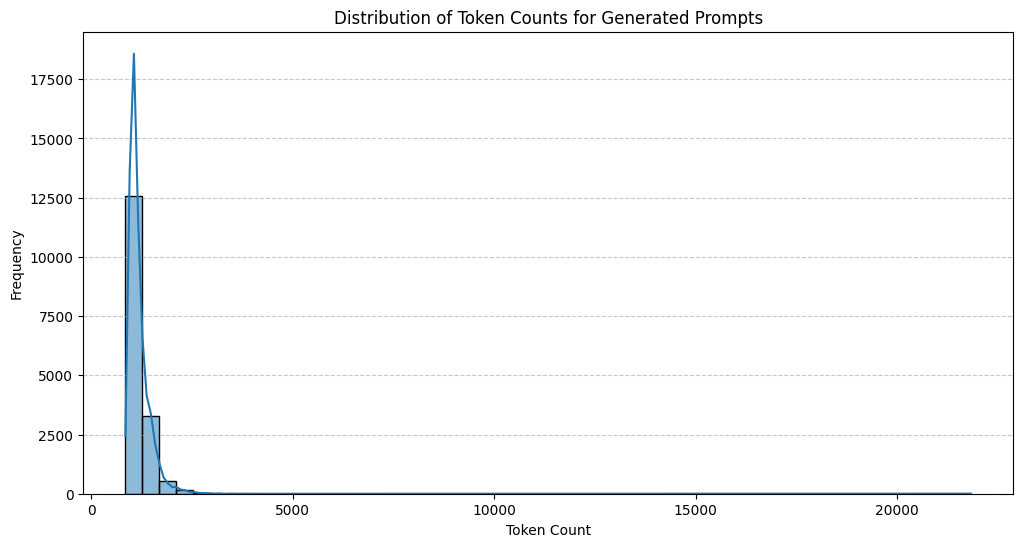

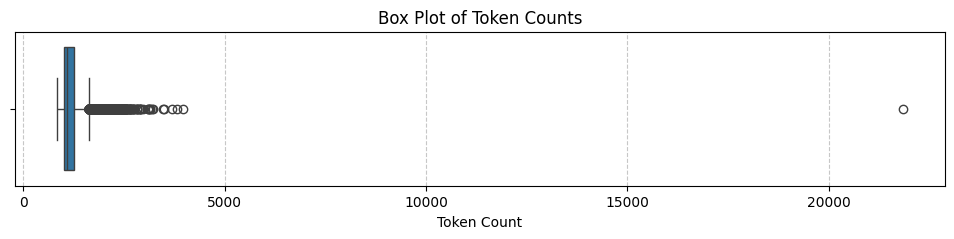

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

token_counts_list = list(hf_dataset['token_count'])

plt.figure(figsize=(12, 6))
sns.histplot(token_counts_list, bins=50, kde=True)
plt.title('Distribution of Token Counts for Generated Prompts')
plt.xlabel('Token Count')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

plt.figure(figsize=(12, 2))
sns.boxplot(x=token_counts_list)
plt.title('Box Plot of Token Counts')
plt.xlabel('Token Count')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

### Outlier Data by Token Count

Let's identify and display the research papers that have a token count exceeding the `max_model_tokens` threshold (which is set to 4096).

In [ ]:
outlier_records = hf_dataset.filter(lambda x: x['token_count'] > max_model_tokens)

print(f"Found {len(outlier_records)} records with token count > {max_model_tokens}:")

for i, record in enumerate(outlier_records):
    print(f"Record {i+1}:")
    print(f"  Title: {record['title']}")
    print(f"  Token Count: {record['token_count']}")
    print("\n" + "-" * 50 + "\n")

Filter:   0%|          | 0/16590 [00:00<?, ? examples/s]

Found 1 records with token count > 4096:
Record 1:
  Title: Te Kaunati Hikahika a Ōpōtiki Mai Tawhiti: Ka hika i taku ahi, kimihia e Te Whakatōhea te ara o te tikanga i pai ai te noho i te ao nei
  Token Count: 21828

--------------------------------------------------



In [ ]:
max_token_index = hf_dataset['token_count'].index(max_tokens)
outlier_df_record = df.iloc[[max_token_index]]
display(outlier_df_record)

,title,authors,year,subjects,abstract,text,record_id_hash
14700,Te Kaunati Hikahika a Ōpōtiki Mai Tawhiti: Ka ...,"Maxwell, Te Kahautu",2019,Ōpōtiki Mai Tawhiti Kapa Haka,Pinepine Te Kura\r\n1\t\r\n1.1\tTe Rongopai \r...,Te Kaunati Hikahika a Ōpōtiki Mai Tawhiti: Ka ...,ceac8ab98d12d779c78d94fafa3ea80de437d2bb3964b4...


In [ ]:
max_model_tokens = 4096
hf_dataset_filtered = hf_dataset.filter(lambda x: x['token_count'] <= max_model_tokens)

print(f"Original dataset size: {len(hf_dataset)} records")
print(f"Filtered dataset size (token_count <= {max_model_tokens}): {len(hf_dataset_filtered)} records")
print(hf_dataset_filtered)

Filter:   0%|          | 0/16590 [00:00<?, ? examples/s]

Original dataset size: 16590 records
Filtered dataset size (token_count <= 4096): 16589 records
Dataset({
    features: ['title', 'authors', 'year', 'subjects', 'abstract', 'text', 'record_id_hash', 'prompt', 'token_count'],
    num_rows: 16589
})


In [ ]:
from datasets import Dataset

DATA_PATH = "/content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/stage2_colab/HuggingFace_Dataset"

# if hf_dataset_filtered is already in memory
hf_dataset_filtered.save_to_disk(DATA_PATH)

print("Dataset saved to Drive")

Saving the dataset (0/1 shards):   0%|          | 0/16589 [00:00<?, ? examples/s]

Dataset saved to Drive
